# 2. How the agent searched for the fusion design

**What this notebook shows.** How the fusion design was found (TASK.md Step 2), from the saved
records only; nothing is trained here.

**The agent has two layers.**
1. **Inner agent (deterministic, no language model).** Inside one *version*, it runs at most 20
   experiments on seed 0's development patients. It opens one candidate per family, follows the
   family that leads, drops a family once it is clearly behind, tunes the best few, and picks the
   simplest candidate that the best one does not *clearly* beat (clearly = wins in ≥ 90% of 2,000
   paired bootstrap resamples). Every step is written to an append-only log with its reason.
2. **Outer layer (a language-model agent, between versions).** It reads the logs, writes down why
   the version did or did not work, and designs the next version with **one** new idea,
   pre-registered (hypothesis, prediction, what would prove it wrong) before the run.
   Its protocol is `docs/loop.md`; everything it decided is in `decisions/` (one file per version).

The test sets were never used during the search.

In [1]:
# Run from anywhere inside the repository: move to its root so every path below works.
import os, sys
from pathlib import Path
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from src.eval import final_view as fv

fv.style()
pd.set_option("display.max_colwidth", 200)
print("Repository:", root.name)

Repository: lung-fm-fusion


## 1. The 11 versions

- *Agent's winner*: what the inner agent's selection rule chose.
- *Best experiment*: the highest development AUROC in that version (often not chosen, because it
  did not *clearly* beat a simpler candidate).
- *Winner's curse*: how much choosing the best of many experiments inflates its score (estimated
  over all experiments so far); small values mean selection noise is under control.
- `_uvg` rows: two earlier versions re-run once the third model (GenBio-PathFM) was available.

In [2]:
versions = fv.versions_table("artifacts/versions")
versions

,Idea,Models,Experiments,Agent's winner,Winner AUROC,Best experiment,Best AUROC,Gain vs row 5,Current best,Winner's curse
Version,,,,,,,,,,
v01,"Fixed sweep of 11 recipes (early, late, learned)","U, V",13,L2,0.7967,L4,0.8162,-0.0025,v01,0.0088
v01_uvg,Re-baseline of v01 on three models,"U, V, G",14,L1,0.7964,L4,0.8186,-0.0028,v01_uvg,0.0077
v02,Adaptive search; learned age-and-sex tokens,"U, V",15,L1:raw,0.7991,L4:ple,0.8118,-0.0001,v01,0.0102
v03,Age and sex as a Bayesian prior,"U, V",20,L1:raw,0.7991,L4:ple,0.8118,-0.0001,v01,0.0111
v04,Tile-level attention MIL,"U, V",17,M1:ft,0.8536,M2:ple,0.8580,0.0544,v04,0.0029
v04_uvg,Re-baseline of v04 on three models,"U, V, G",17,M2:ft,0.8508,M2:ft,0.8508,0.0517,v04_uvg,0.0026
v05,One MIL expert per model × age-and-sex prior,"U, V",20,M1:ft,0.8536,X1:raw,0.8578,0.0544,v04,0.0052
v06,Composition pooling (+ GenBio-PathFM),"U, V, G",20,M2:ft,0.8508,X1:raw,0.8579,0.0517,v04_uvg,0.0049
v07,CLAM experts,"U, V, G",20,X1:raw,0.8579,C1:raw,0.8614,0.0588,v04_uvg,0.0039


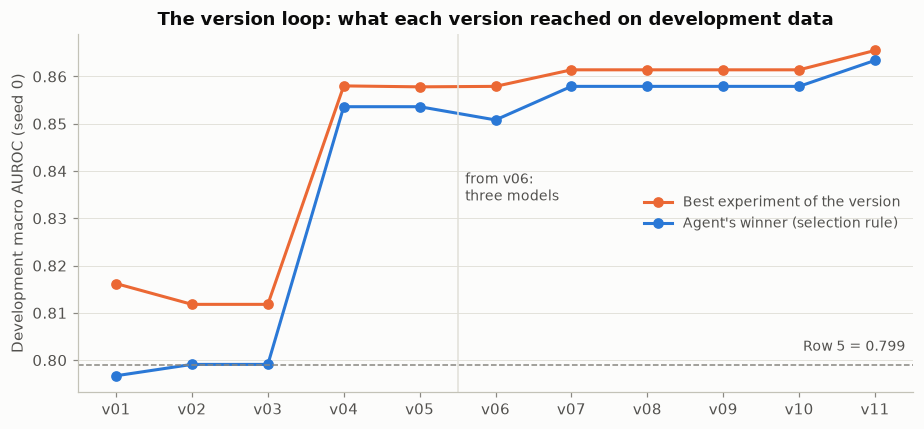

In [3]:
fv.plot_versions(versions); plt.show()

**What the versions taught.**
- **v04** brought the one big jump: reading individual tiles with learned attention instead of
  averaging all tiles (+0.055).
- Every later idea moved the score by less than 0.01: separate models per foundation model
  (v05), different tile pooling (v06–v08), ensembles (v09), age and sex choosing tiles (v10).
- **v11** (an extra coarse training target: grade groups) was the only later change that helped
  beyond its control; its winner H1 became the final design.
- Age and sex added 0 to +0.005 in every form tried.

The full reasoning, version by version: `decisions/SUMMARY.md` and `decisions/v01.md` … `v11.md`.

In [4]:
display(Markdown(Path("decisions/SUMMARY.md").read_text()))

# Summary of the version loop (v01–v11)

Written 2026-11-02, when the loop ended at the user's decision ("I think 11 budget is good
enough"). All numbers are seed 0, development data (162 patients, 8-fold out-of-fold), macro
AUROC; the test set was not read during the loop. Per-version detail: `vNN.md`; leaderboard:
`README.md`.

## 1. What was searched

Each version is one structural change, pre-registered before its run, searched by the
deterministic inner agent (≤ 20 experiments, 30-minute cap each, paired-bootstrap decisions),
and analysed by the outer language-model layer (docs/loop.md). 11 versions + 2 re-baselines,
236 experiments. v01–v05: UNI2-h + Virchow2; v06–v11: UNI2-h, Virchow2, GenBio-PathFM.

| Version | Structural change | Best candidate (AUROC) | Agent's winner | Outcome |
| --- | --- | --- | --- | --- |
| v01 | Fixed sweep of 11 recipes (early, late, learned), shortlist, tune | L4 tuned 0.816 (bal. acc. low) | L2 tuned 0.797 | Below row 5 |
| v02 | Adaptive policy; learned age-and-sex tokens | L1:raw 0.799 | L1:raw 0.799 | Encodings add nothing |
| v03 | Age and sex as a Bayesian prior (log-linear pools) | P1:raw 0.807 | L1:raw 0.799 | Ceiling ~0.81 on mean-pooled vectors |
| v04 | Tile-level attention MIL (1,024 tiles per slide) | M1:ft 0.854 | M1:ft 0.854 | **+0.055**: the main gain |
| v05 | One MIL expert per model × age-and-sex expert (product of experts) | X1:raw 0.858 | M1:ft 0.854 | Product best fusion form; fitted weights lose |
| v06 | GenBio-PathFM added; composition pooling | X1:raw 0.858 | M2:ft 0.851 | Falsified: relevance weighting is the gain |
| v07 | CLAM experts (pseudo-labelled tiles) | C1:raw 0.861 | X1:raw 0.858 | Small, unresolved gain |
| v08 | Spatial context tokens (neighbourhood means) | C1:raw 0.861 | X1:raw 0.858 | Falsified: capacity hurts |
| v09 | Ensembles of expert types | C1:raw 0.861 | X1:raw 0.858 | Falsified: experts share errors |
| v10 | Age and sex as attention queries | C1:raw 0.861 | X1:raw 0.858 | Falsified: no better than a prior |
| v11 | Grade-group auxiliary target | H2:raw 0.866 | **H1:raw 0.863** | Supported (vs X1 96%) |

## 2. Current best and the final design

**Current best: v11, winner H1:raw** (AUROC 0.863 [0.831, 0.894], balanced accuracy 0.521). It
clearly beats the previous current best on U, V, G (`v04_uvg`, M2:ft 0.851): gain +0.013
[−0.000, +0.028], won in 97.4% of resamples, balanced accuracy +0.019.

**H1:raw, the agent-selected design:** per foundation model (UNI2-h, Virchow2, GenBio-PathFM),
a gated-attention MIL expert over 1,024 cached tiles (projection to d = 32, 100 epochs, AdamW,
weight decay 0.01, dropout 0.25, 256 tiles per step, 3 seeds averaged), trained with a
seven-class head and an auxiliary grade-group head (In situ; Lepidic; Acinar + Papillary;
Solid + Micropapillary + Cribriform; weight 0.5). No age and sex inside the experts. Fusion:
`z = mean over models of log p_model + log p(class | age, sex)`, the latter from a
class-weighted logistic regression on raw age and sex (C = 1). Zero fitted fusion weights.

**Matched rows of H1:raw (same recipe, seed 0):** age and sex alone 0.611; UNI2-h 0.856;
Virchow2 0.854; GenBio-PathFM 0.841; UNI2-h + age and sex 0.859; U + V + G without age and sex
0.860. Gain over row 5 (0.799): +0.064 [+0.033, +0.093] (from the record of T016).

**Global winner's curse:** +0.003 AUROC over the 146 experiments of the U, V, G block (README.md),
smaller than the gain over row 5 but as large as the gains of v05–v11 over one another.

## 3. What was learned

1. **The gain over row 5 comes from the slide representation.** Weighting tiles by a learned
   relevance (attention MIL) instead of averaging them: 0.80 → 0.85 (v04). Uniform averages,
   in embedding or probability space, stay at ~0.80 (v06).
2. **Age and sex add 0 to +0.005 in every form** (columns, piecewise-linear and learned
   tokens, prior, FiLM, attention queries). Only the product of experts makes the gain
   consistent (89–94% of resamples). They carry little beyond the image (alone 0.61–0.63).
3. **The three foundation models are largely redundant.** Fitted weights ≤ 0.1 for Virchow2
   and GenBio-PathFM next to UNI2-h; joint networks get worse when a model is added.
4. **With ~142 training slides, added capacity loses** (v06, v07 class-specific attention,
   v08); zero-parameter combinations win; tuning never helped the tile-level models.
5. **All experts share their errors** (v09), concentrated on Lepidic, Acinar and Papillary;
   the auxiliary grade-group target (v11) is the only later change that helped beyond its
   control.

## 4. Recommended final design and secondary designs

Frozen in `conf/final.yaml` before the test set is read:

| Role | Design | Seed 0 dev AUROC | Why |
| --- | --- | --- | --- |
| **Primary** | **H1:raw** (v11) | 0.863 | The agent's own selection; current best |
| Secondary | H2:raw (v11) | 0.866 | Highest development AUROC |
| Secondary | C1:raw (v07) | 0.861 | Best design without the grade-group head |

All three are reported on every seed whatever they score; the primary is never changed after
the test numbers are seen.

## 5. Limits

- Every number above is from seed 0 development data, on which ~236 experiments and 11 design
  decisions were made; the differences between v05–v11 (≤ 0.008) are of the size of the
  selection bias.
- Seeds 1–4 share development patients with seed 0's test set and vice versa; their test results
  are secondary (docs/methods.md D22).

## 6. Final evaluation (stage 12)

Per seed s ∈ {0, …, 4}, for each design: 8-fold development CV; one fit on all 162 development
patients; one prediction of the 41 test patients. Rows under each design's own recipe: fused +
age and sex, each model alone, best single model (chosen on development) + age and sex, age and
sex alone, fused without age and sex; plus the original rows 1–5 (stage 09). Claim rule (fixed in
advance): fused beats a row on a seed if the paired 95% CI of the test AUROC gain excludes 0.

```
uv run --no-sync python -m scripts.12_final_eval --seed <s> --device cuda:0|cuda:1
uv run --no-sync python -m scripts.13_final_report
```

Results: `docs/results.md` and `artifacts/final/`.


## 2. Inside one version: the decision log of v11

Every decision the inner agent took, with its rule and its reason, in order:

In [5]:
fv.decisions("v11")

,Rule,Reason
ID,,
s0-D001,open,"Open with the simplest candidate of each family plus every recipe of the families opened in full at fixed values: E1:raw, L1:raw, P1:raw, N1:ft, M1:ft, X1:raw, A1:raw, C1:raw, C2:raw, K1:raw, K2:r..."
s0-D002,drop,"Drop clam: the best experiment s0-T017 (H2:raw screen, AUROC 0.866) beats the clam family's best s0-T008 (C1:raw screen, AUROC 0.861) in 92% of resamples (≥ 90%)."
s0-D003,drop,"Drop ctx: the best experiment s0-T017 (H2:raw screen, AUROC 0.866) beats the ctx family's best s0-T011 (K2:raw screen, AUROC 0.857) in 95% of resamples (≥ 90%)."
s0-D004,drop,"Drop ens: the best experiment s0-T017 (H2:raw screen, AUROC 0.866) beats the ens family's best s0-T012 (Z1:raw screen, AUROC 0.861) in 93% of resamples (≥ 90%)."
s0-D005,tune_start,"Start tuning (the exploration budget is used): the best screened candidate of each recipe, top 3: s0-T003 (P1:raw screen, AUROC 0.805), s0-T002 (L1:raw screen, AUROC 0.801), s0-T001 (E1:raw screen..."
s0-D006,final_selection,"s0-T017 (H2:raw screen, AUROC 0.866) has the highest AUROC but does not clearly beat the simpler s0-T016 (H1:raw screen, AUROC 0.863): it wins in 75% of resamples (needs ≥ 90%) and its balanced ac..."


And every experiment it ran (development AUROC over 8 folds, gain over row 5):

In [6]:
fv.experiments("v11")

,Candidate,Mode,Status,AUROC,Bal. acc.,vs row 5,Seconds
ID,,,,,,,
s0-T001,E1:raw,screen,done,0.790,0.448,-0.010,10.1
s0-T002,L1:raw,screen,done,0.801,0.425,0.002,7.0
s0-T003,P1:raw,screen,done,0.805,0.423,0.006,6.6
s0-T004,N1:ft,screen,done,0.770,0.388,-0.029,7.1
s0-T005,M1:ft,screen,done,0.834,0.508,0.035,51.5
s0-T006,X1:raw,screen,done,0.858,0.520,0.059,54.3
s0-T007,A1:raw,screen,done,0.797,0.453,-0.002,53.1
s0-T008,C1:raw,screen,done,0.861,0.524,0.062,62.9
s0-T009,C2:raw,screen,done,0.852,0.469,0.053,63.2


The full human-readable log (each experiment, why it was chosen, all scores) is
`artifacts/versions/v11/seed_0/agent/decision_log.md`; the raw record is `trials.jsonl` next to it.
Change `"v11"` above to any other version (`"v01"` … `"v11"`) to see its decisions.

## 3. Reproduce a version

Each version is the shared code plus its config (`conf/versions/vNN.yaml`). To repeat one on the
development data (about 30–60 minutes on one GPU):

```bash
uv run --no-sync python -m scripts.10_fusion_search --seed 0 --dev --config conf/versions/v11.yaml
```

In this repository the run's record already exists, so the agent reads it, recognises every
experiment as done and adds nothing (resume). To repeat a version from scratch, run the command in
a fresh clone (with the cached features copied in).